<table style="width:100%">
<tr>
<td style="vertical-align:middle; text-align:left;">
<font size="2">
<a href="https://sebastianraschka.com">Sebastian Raschka</a> 著作《<a href="http://mng.bz/orYv">从零构建大语言模型 (Build a Large Language Model From Scratch)</a>》配套补充代码<br>
<br>代码仓库：<a href="https://github.com/rasbt/LLMs-from-scratch">https://github.com/rasbt/LLMs-from-scratch</a>
</font>
</td>
<td style="vertical-align:middle; text-align:left;">
<a href="http://mng.bz/orYv"><img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/cover-small.webp" width="100px"></a>
</td>
</tr>
</table>

第4章：从零开始实现GPT模型来生成文本

In [1]:
from importlib.metadata import version

print("matplotlib version:", version("matplotlib"))
print("torch version:", version("torch"))
print("tiktoken version:", version("tiktoken"))

matplotlib version: 3.10.7
torch version: 2.14.1
tiktoken version: 0.14.0


-在本章中，我们实现了一个类似gpt的LLM架构；下一章将重点介绍如何培养这名大语言模型 (LLM)

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/01.webp" width="500px">

&nbsp;
## 4.1 编写大语言模型架构代码

第一章讨论了像GPT和Llama这样的模型，它们顺序生成单词，并基于原始变压器架构的解码器部分
-因此，这些大语言模型 (LLM)通常被称为“解码器类”大语言模型 (LLM)
-与传统的深度学习模型相比，llm更大，主要是因为它们有大量的参数，而不是代码的数量
-我们会看到许多元素在LLM的架构中是重复的

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/02.webp" width="600px">

-在前面的章节中，为了便于说明，我们为令牌输入和输出使用了较小的嵌入维度，确保它们适合单个页面
-在本章中，我们考虑嵌入和模型大小类似于一个小型GPT-2模型
-我们将专门编码最小GPT-2模型的架构（1.24亿个参数），如Radford等人的[语言模型是无监督的多任务学习者]（https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf）中所述（注意，最初的报告将其列出为117M个参数，但后来在模型权重存储库中进行了更正）
第6章将展示如何将预训练的权重加载到我们的实现中，它将兼容345,762和1542万个参数的模型大小

- 包含 1.24 亿（124M）参数的 GPT-2 模型配置详情如下：

In [2]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 1024, # Context length
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of attention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

- 我们使用简短的变量名以避免后续代码行过长
- `"vocab_size"` 表示词表大小为 50,257 个词，由第 2 章讨论的 BPE 分词器提供支持
- `"context_length"` 表示模型的最大输入 token 数量，由第 2 章介绍的位置嵌入所决定
- `"emb_dim"` 是 token 输入的嵌入维度，将每个输入 token 转换为 768 维向量
- `"n_heads"` 是第 3 章实现的多头注意力机制中的注意力头数量
- `"n_layers"` 是模型内 Transformer 块的数量，我们将在接下来的章节中实现它们
- `"drop_rate"` 是第 3 章讨论的 dropout 机制的丢弃率；0.1 意味着在训练期间随机丢弃 10% 的隐藏单元以减轻过拟合
- `"qkv_bias"` 决定多头注意力机制（来自第 3 章）中的 `Linear` 层在计算查询（Q）、键（K）和值（V）张量时是否包含偏置向量；我们禁用了该选项，这是现代大语言模型的标准做法；不过，在第 5 章中将 OpenAI 预训练的 GPT-2 权重加载到我们的复现实现中时，我们会重新启用它

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/03.webp" width="500px">

In [3]:
import torch
import torch.nn as nn


class DummyGPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        
        # Use a placeholder for TransformerBlock
        self.trf_blocks = nn.Sequential(
            *[DummyTransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        
        # Use a placeholder for LayerNorm
        self.final_norm = DummyLayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits


class DummyTransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        # A simple placeholder

    def forward(self, x):
        # This block does nothing and just returns its input.
        return x


class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()
        # The parameters here are just to mimic the LayerNorm interface.

    def forward(self, x):
        # This layer does nothing and just returns its input.
        return x

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/04.webp?123" width="500px">

In [4]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

batch = []

txt1 = "Every effort moves you"
txt2 = "Every day holds a"

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


In [5]:
torch.manual_seed(123)
model = DummyGPTModel(GPT_CONFIG_124M)

logits = model(batch)
print("Output shape:", logits.shape)
print(logits)

Output shape: torch.Size([2, 4, 50257])
tensor([[[-1.2034,  0.3201, -0.7130,  ..., -1.5548, -0.2390, -0.4667],
         [-0.1192,  0.4539, -0.4432,  ...,  0.2392,  1.3469,  1.2430],
         [ 0.5307,  1.6720, -0.4695,  ...,  1.1966,  0.0111,  0.5835],
         [ 0.0139,  1.6754, -0.3388,  ...,  1.1586, -0.0435, -1.0400]],

        [[-1.0908,  0.1798, -0.9484,  ..., -1.6047,  0.2439, -0.4530],
         [-0.7860,  0.5581, -0.0610,  ...,  0.4835, -0.0077,  1.6621],
         [ 0.3567,  1.2698, -0.6398,  ..., -0.0162, -0.1296,  0.3717],
         [-0.2407, -0.7349, -0.5102,  ...,  2.0057, -0.3694,  0.1814]]],
       grad_fn=<UnsafeViewBackward0>)


---

**说明**

- 如果你在 Windows 或 Linux 上运行此代码，上面输出的结果值可能会类似于以下内容：

```
Output shape: torch.Size([2, 4, 50257])
tensor([[[-0.9289,  0.2748, -0.7557,  ..., -1.6070,  0.2702, -0.5888],
         [-0.4476,  0.1726,  0.5354,  ..., -0.3932,  1.5285,  0.8557],
         [ 0.5680,  1.6053, -0.2155,  ...,  1.1624,  0.1380,  0.7425],
         [ 0.0447,  2.4787, -0.8843,  ...,  1.3219, -0.0864, -0.5856]],

        [[-1.5474, -0.0542, -1.0571,  ..., -1.8061, -0.4494, -0.6747],
         [-0.8422,  0.8243, -0.1098,  ..., -0.1434,  0.2079,  1.2046],
         [ 0.1355,  1.1858, -0.1453,  ...,  0.0869, -0.1590,  0.1552],
         [ 0.1666, -0.8138,  0.2307,  ...,  2.5035, -0.3055, -0.3083]]],
       grad_fn=<UnsafeViewBackward0>)
```

- 由于这些只是随机生成的数字，因此无需担心，你可以继续阅读本章的其余部分，不会受到任何影响
- 造成这种差异的一个可能原因是跨操作系统的 `nn.Dropout` 行为有所不同，这取决于 PyTorch 的编译方式，详见 [PyTorch issue 追踪器上的相关讨论](https://github.com/pytorch/pytorch/issues/121595)

---

&nbsp;
## 4.2 使用层归一化（Layer Normalization）规范化激活值

- 层归一化（Layer Normalization），通常称为 LayerNorm（[Ba 等人，2016](https://arxiv.org/abs/1607.06450)），将神经网络层的激活值中心化为均值 0，并将方差归一化为 1
- 这可以稳定训练过程，并使模型更快地收敛到有效的权重
- 在我们稍后实现的 Transformer 块中，层归一化既应用在多头注意力模块之前，也应用在其之后；此外，它还应用于最终的输出层之前

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/05.webp" width="600px">

- 让我们通过将一个小输入样本传入一个简单的神经网络层，来看看层归一化是如何工作的：

In [6]:
torch.manual_seed(123)

# create 2 training examples with 5 dimensions (features) each
batch_example = torch.randn(2, 5) 

layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
out = layer(batch_example)
print(out)

tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


In [7]:
# 拆分 Sequential的示例
torch.manual_seed(123)

# create 2 training examples with 5 dimensions (features) each
batch_example = torch.randn(2, 5) 
print("batch_example:", batch_example)

layer = nn.Linear(5, 6)
print("layer weights:", layer.weight)
print("layer biases:", layer.bias)


activation = nn.ReLU()

out = layer(batch_example)
out = activation.forward(out)
print(out)

batch_example: tensor([[-0.1115,  0.1204, -0.3696, -0.2404, -1.1969],
        [ 0.2093, -0.9724, -0.7550,  0.3239, -0.1085]])
layer weights: Parameter containing:
tensor([[ 0.3162,  0.0833,  0.1223,  0.4317, -0.2017],
        [ 0.1417, -0.1990,  0.3196,  0.3572, -0.4123],
        [ 0.3818,  0.2136,  0.1949,  0.1841,  0.3718],
        [-0.0590, -0.3782, -0.1283, -0.3150,  0.0296],
        [-0.0835, -0.2399, -0.0407,  0.4237, -0.0353],
        [ 0.0142, -0.0697,  0.0703,  0.3985,  0.2735]], requires_grad=True)
layer biases: Parameter containing:
tensor([ 0.1587,  0.0972,  0.1054,  0.1728, -0.0578, -0.4156],
       requires_grad=True)
tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


- 让我们计算上述 2 个输入样本各自的均值和方差：

In [8]:
mean = out.mean(dim=-1, keepdim=True)
var = out.var(dim=-1, keepdim=True)

print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)


- 归一化是独立应用于两个输入样本（行）的；使用 dim=-1 表示沿着最后一个维度（在此示例中为特征维度）而不是行维度来进行计算

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/06.webp" width="600px">

- 减去均值并除以方差的平方根（标准差），使得输入在列（特征）维度上的均值为 0，方差为 1：

In [9]:
out_norm = (out - mean) / torch.sqrt(var)
print("Normalized layer outputs:\n", out_norm)

mean = out_norm.mean(dim=-1, keepdim=True)
var = out_norm.var(dim=-1, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

Normalized layer outputs:
 tensor([[ 0.6159,  1.4126, -0.8719,  0.5872, -0.8719, -0.8719],
        [-0.0189,  0.1121, -1.0876,  1.5173,  0.5647, -1.0876]],
       grad_fn=<DivBackward0>)
Mean:
 tensor([[9.9341e-09],
        [0.0000e+00]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


- 每个输入都中心化在 0 且具有单位方差 1；为了提高可读性，我们可以禁用 PyTorch 的科学计数法显示：

In [10]:
torch.set_printoptions(sci_mode=False)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.0000],
        [0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


- 上面我们对每个输入的特征进行了归一化
- 现在，基于相同的思路，我们可以实现一个 `LayerNorm` 类：

In [11]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift

**缩放与平移（Scale and shift）**

- 请注意，除了通过减去均值并除以方差来进行归一化之外，我们还添加了两个可训练参数：`scale`（缩放）和 `shift`（平移）参数
- 初始的 `scale`（乘以 1）和 `shift`（加上 0）值不会产生任何初始改变；然而，`scale` 和 `shift` 是可训练参数，如果大语言模型在训练任务中发现调整它们可以提高性能，便会自动对其进行更新
- 这使得模型能够学习最适合其处理数据的缩放和平移方式
- 请注意，在计算方差的平方根之前，我们还添加了一个很小的数值（`eps`）；这是为了在方差为 0 时避免除以零错误

**有偏方差（Biased variance）**
- 在上面的方差计算中，设置 `unbiased=False` 意味着使用公式 $\frac{\sum_i (x_i - \bar{x})^2}{n}$ 来计算方差，其中 n 是样本大小（这里是特征数或列数）；该公式不包含贝塞尔校正（Bessel's correction，分母中使用 `n-1`），因此提供的是方差的有偏估计
- 对于大语言模型而言，嵌入维度 `n` 非常大，使用 n 和 `n-1` 之间的差异微乎其微
- 然而，GPT-2 在归一化层中使用的是有偏方差进行训练的，这也是我们在实现中采用该设置的原因，以便与后续章节中加载的预训练权重保持兼容

- 现在让我们在实践中测试一下 `LayerNorm`：

In [12]:
ln = LayerNorm(emb_dim=6)
out_ln = ln(out)

In [13]:
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, unbiased=False, keepdim=True)

print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[ 0.0000],
        [-0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.9995],
        [0.9997]], grad_fn=<VarBackward0>)


- 方差不是严格等于 1，因为我们使用了 `eps`

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/07.webp" width="600px">

&nbsp;
## 4.3 使用 GELU 激活函数实现前馈网络

- 在本节中，我们将实现一个作为大语言模型 Transformer 块一部分的小型神经网络子模块
- 我们从激活函数开始
- 在深度学习中，ReLU（修正线性单元，Rectified Linear Unit）激活函数因其在各种神经网络架构中的简洁性与有效性而被广泛使用
- 在大语言模型中，除了传统的 ReLU 之外，还使用了多种其他类型的激活函数；其中两个著名的例子是 GELU（高斯误差线性单元，Gaussian Error Linear Unit）和 SwiGLU（Swish 门控线性单元，Swish-Gated Linear Unit）
- GELU 和 SwiGLU 是更复杂、平滑的激活函数，分别结合了高斯分布和 sigmoid 门控线性单元，与简单的分段线性函数 ReLU 相比，能为深度学习模型提供更优异的性能

- GELU（[Hendrycks and Gimpel 2016](https://arxiv.org/abs/1606.08415)）有几种实现方式；精确版本定义为 $\text{GELU}(x) = x \cdot \Phi(x)$，其中 $\Phi(x)$ 是标准高斯分布的累积分布函数
- 在实践中，通常会实现一个计算成本较低的近似公式：$\text{GELU}(x) \approx 0.5 \cdot x \cdot \left(1 + \tanh\left[\sqrt{\frac{2}{\pi}} \cdot \left(x + 0.044715 \cdot x^3\right)\right]\right)$（原始 GPT-2 模型也是使用该近似公式训练的）

In [14]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x, 3))
        ))

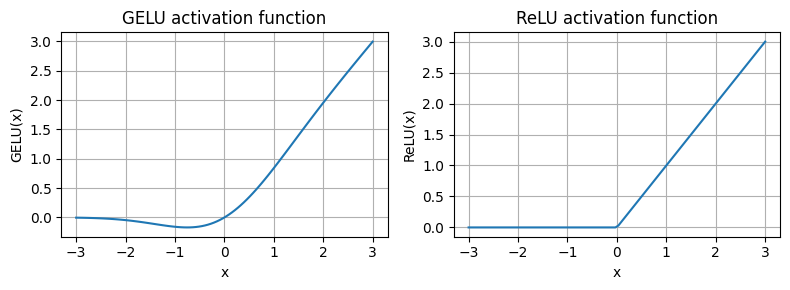

In [15]:
import matplotlib.pyplot as plt

gelu, relu = GELU(), nn.ReLU()

# Some sample data
x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)

plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)

plt.tight_layout()
plt.show()

- 可以看到，ReLU 是一个分段线性函数，如果输入为正数则直接输出输入值，否则输出零
- GELU 是一个平滑的非线性函数，它近似于 ReLU，但在负值区间具有非零梯度（大约在 -0.75 处除外）

- 接下来，让我们实现小型神经网络模块 `FeedForward`，稍后我们将在大语言模型的 Transformer 块中使用它：

In [16]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
        )

    def forward(self, x):
        return self.layers(x)

In [17]:
print(GPT_CONFIG_124M["emb_dim"])

768


<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/09.webp?12" width="600px">

In [18]:
ffn = FeedForward(GPT_CONFIG_124M)

# input shape: [batch_size, num_token, emb_size]
x = torch.rand(2, 3, 768) 
out = ffn(x)
print(out.shape)

torch.Size([2, 3, 768])


<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/10.webp" width="600px">

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/11.webp" width="600px">

&nbsp;
## 4.4 添加捷径连接（Shortcut Connections）

- 接下来，我们来讨论捷径连接（shortcut connections，也称跳跃连接 skip connections 或残差连接 residual connections）背后的核心概念
- 捷径连接最初是在计算机视觉领域的深度残差网络（ResNet）中提出的，用于缓解梯度消失问题
- 捷径连接为梯度在网络中流动创建了一条替代的更短路径
- 这是通过将前一层的输出加到后续某一层的输出来实现的，通常跳过中间的一层或多层
- 让我们通过一个小示例网络来说明这个概念：

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/12.webp?123" width="600px">

- 在代码中，实现如下：

In [19]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU())
        ])

    def forward(self, x):
        for layer in self.layers:
            # Compute the output of the current layer
            layer_output = layer(x)
            # Check if shortcut can be applied
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output
        return x


def print_gradients(model, x):
    # Forward pass
    output = model(x)
    target = torch.tensor([[0.]])

    # Calculate loss based on how close the target
    # and output are
    loss = nn.MSELoss()
    loss = loss(output, target)
    
    # Backward pass to calculate the gradients
    loss.backward()

    for name, param in model.named_parameters():
        if 'weight' in name:
            # Print the mean absolute gradient of the weights
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

- 首先，让我们打印**不带**捷径连接时的梯度值：

In [20]:
layer_sizes = [3, 3, 3, 3, 3, 1]  

sample_input = torch.tensor([[1., 0., -1.]])

torch.manual_seed(123)
model_without_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=False
)
print_gradients(model_without_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.00020173587836325169
layers.1.0.weight has gradient mean of 0.0001201116101583466
layers.2.0.weight has gradient mean of 0.0007152041653171182
layers.3.0.weight has gradient mean of 0.001398873864673078
layers.4.0.weight has gradient mean of 0.005049646366387606


- 接下来，让我们打印**带有**捷径连接时的梯度值：

In [21]:
torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=True
)
print_gradients(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.22169791162014008
layers.1.0.weight has gradient mean of 0.20694105327129364
layers.2.0.weight has gradient mean of 0.32896989583969116
layers.3.0.weight has gradient mean of 0.2665732204914093
layers.4.0.weight has gradient mean of 1.3258541822433472


- 从上述输出中可以看到，捷径连接能够防止梯度在靠前的浅层（靠近 `layer.0`）中消失
- 接下来在实现 Transformer 块时，我们将应用这种捷径连接的概念

&nbsp;
## 4.5 在 Transformer 块中连接注意力层与线性层

- 在本节中，我们将前面的概念组合成一个所谓的 Transformer 块（transformer block）
- Transformer 块将前一章的因果多头注意力模块与线性层（我们在前一节实现的前馈神经网络）结合在一起
- 此外，Transformer 块还应用了 dropout 和捷径连接

In [22]:
# If the `previous_chapters.py` file is not available locally,
# you can import it from the `llms-from-scratch` PyPI package.
# For details, see: https://github.com/rasbt/LLMs-from-scratch/tree/main/pkg
# E.g.,
# from llms_from_scratch.ch03 import MultiHeadAttention

from previous_chapters import MultiHeadAttention


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"], 
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        # Shortcut connection for attention block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        # Shortcut connection for feed forward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        return x

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/13.webp?1" width="600px">

- 假设我们有 2 个输入样本，每个样本包含 4 个 token，每个 token 是一个 768 维的嵌入向量；该 Transformer 块先应用自注意力机制，紧接着通过线性层，生成尺寸相似的输出
- 你可以将该输出视为前一章所讨论的上下文向量（context vectors）的增强版本

In [23]:
torch.manual_seed(123)

x = torch.rand(2, 4, 768)  # Shape: [batch_size, num_tokens, emb_dim]
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)

print("GPT_CONFIG_124M", GPT_CONFIG_124M)
print("Input shape:", x.shape)
print("Output shape:", output.shape)

GPT_CONFIG_124M {'vocab_size': 50257, 'context_length': 1024, 'emb_dim': 768, 'n_heads': 12, 'n_layers': 12, 'drop_rate': 0.1, 'qkv_bias': False}
Input shape: torch.Size([2, 4, 768])
Output shape: torch.Size([2, 4, 768])


<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/14.webp?1" width="600px">

### 后续章节

- [4.6 编写 GPT 模型代码](ch04_4.6.ipynb)
- [4.7 生成文本及总结](ch04_4.7.ipynb)